# Algorithms on four twins

Textbook algorithms make the differences between devices concrete, because each one has a known right answer. Every run
below uses device noise and routing, and the results are collected in a scoreboard at the end.

In [1]:
from qputwin_demo import *

connect()
scoreboard = {}

def compare(name, circuit, good, shots=8192):
    results = {b: run(b, circuit, noise=True, routing=True, shots=shots) for b in BACKENDS}
    scoreboard[name] = {NAMES[b]: success(r, good) for b, r in results.items()}
    plot_each_twin(results)
    return results

QPUTwin at http://localhost:8000: ready, 4 twins reachable


## Bernstein-Vazirani

Finds a hidden bitstring with one oracle query. A classical algorithm needs one query per bit.

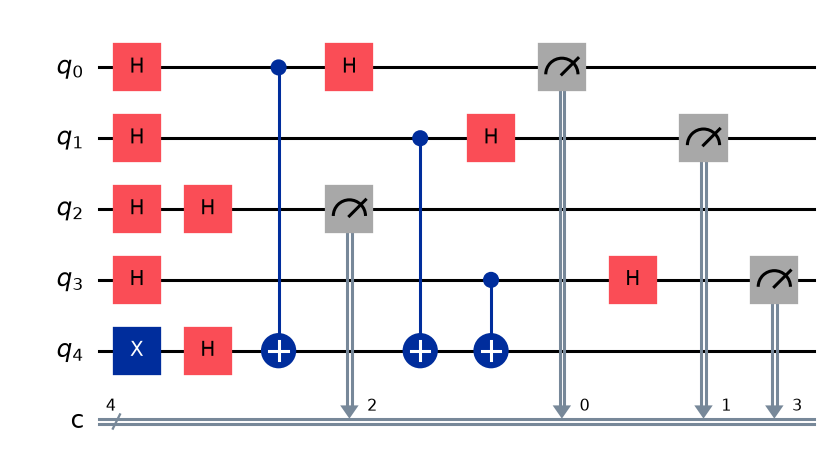

In [2]:
secret = "1011"
circuit = bernstein_vazirani(secret)
draw(circuit)

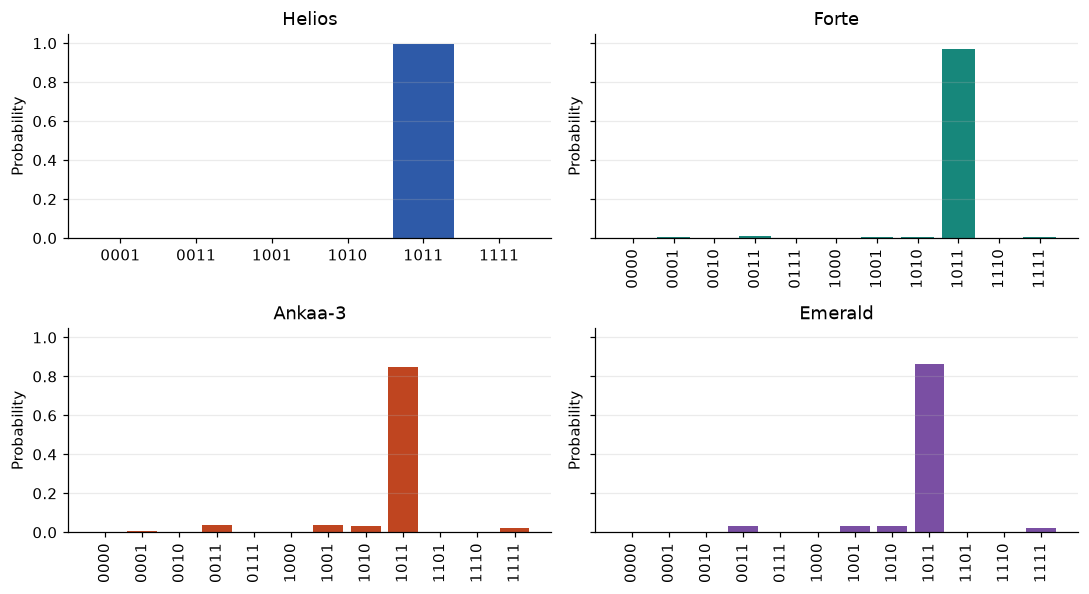

In [3]:
compare("Bernstein-Vazirani", circuit, [secret]);

## Grover search

Two iterations over eight items amplify the marked item, `101`. The ideal success probability is about 0.945.

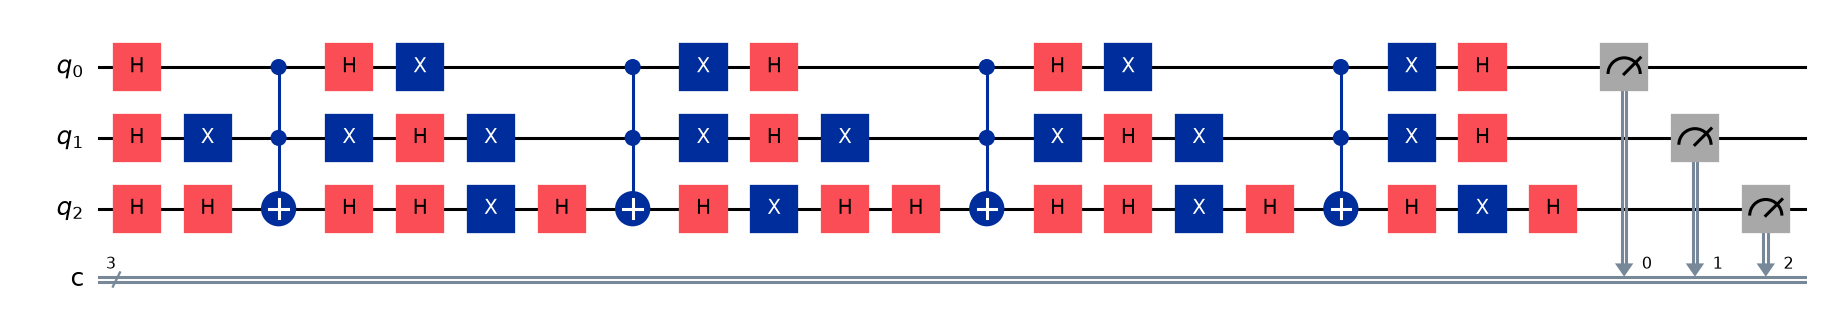

In [4]:
circuit = grover_3("101")
draw(circuit, fold=32)

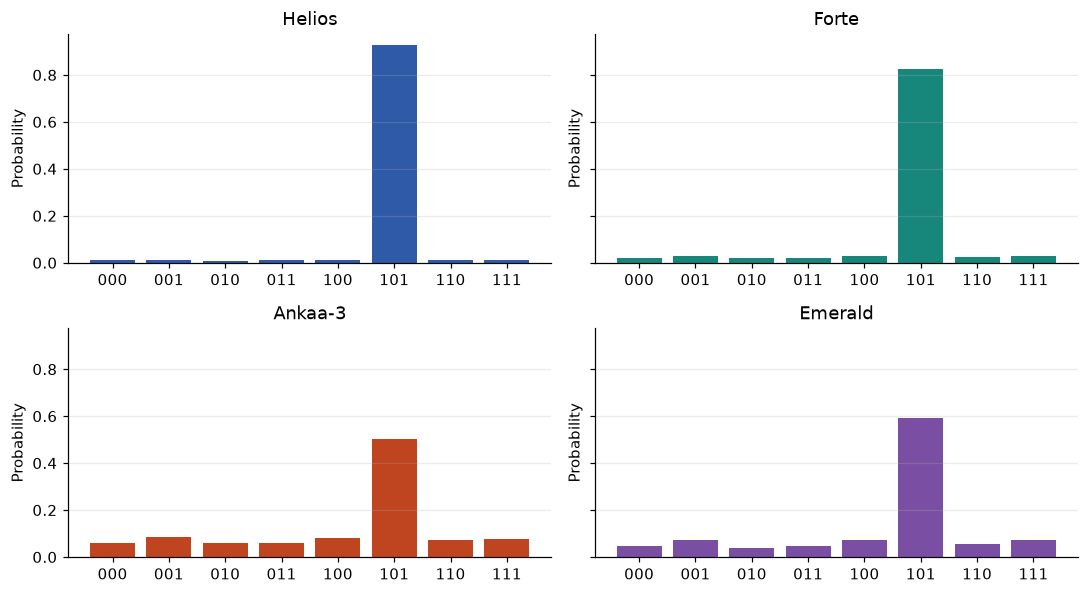

,Native two-qubit gates
Helios,24
Forte,24
Ankaa-3,38
Emerald,41


In [5]:
results = compare("Grover", circuit, ["101"])
pd.Series({NAMES[b]: r["compilation"]["native_two_qubit_count"] for b, r in results.items()}, name="Native two-qubit gates").to_frame()

## Quantum Fourier transform round trip

The QFT then its inverse should return the input exactly. This circuit is dense, so the lattices pay for routing.

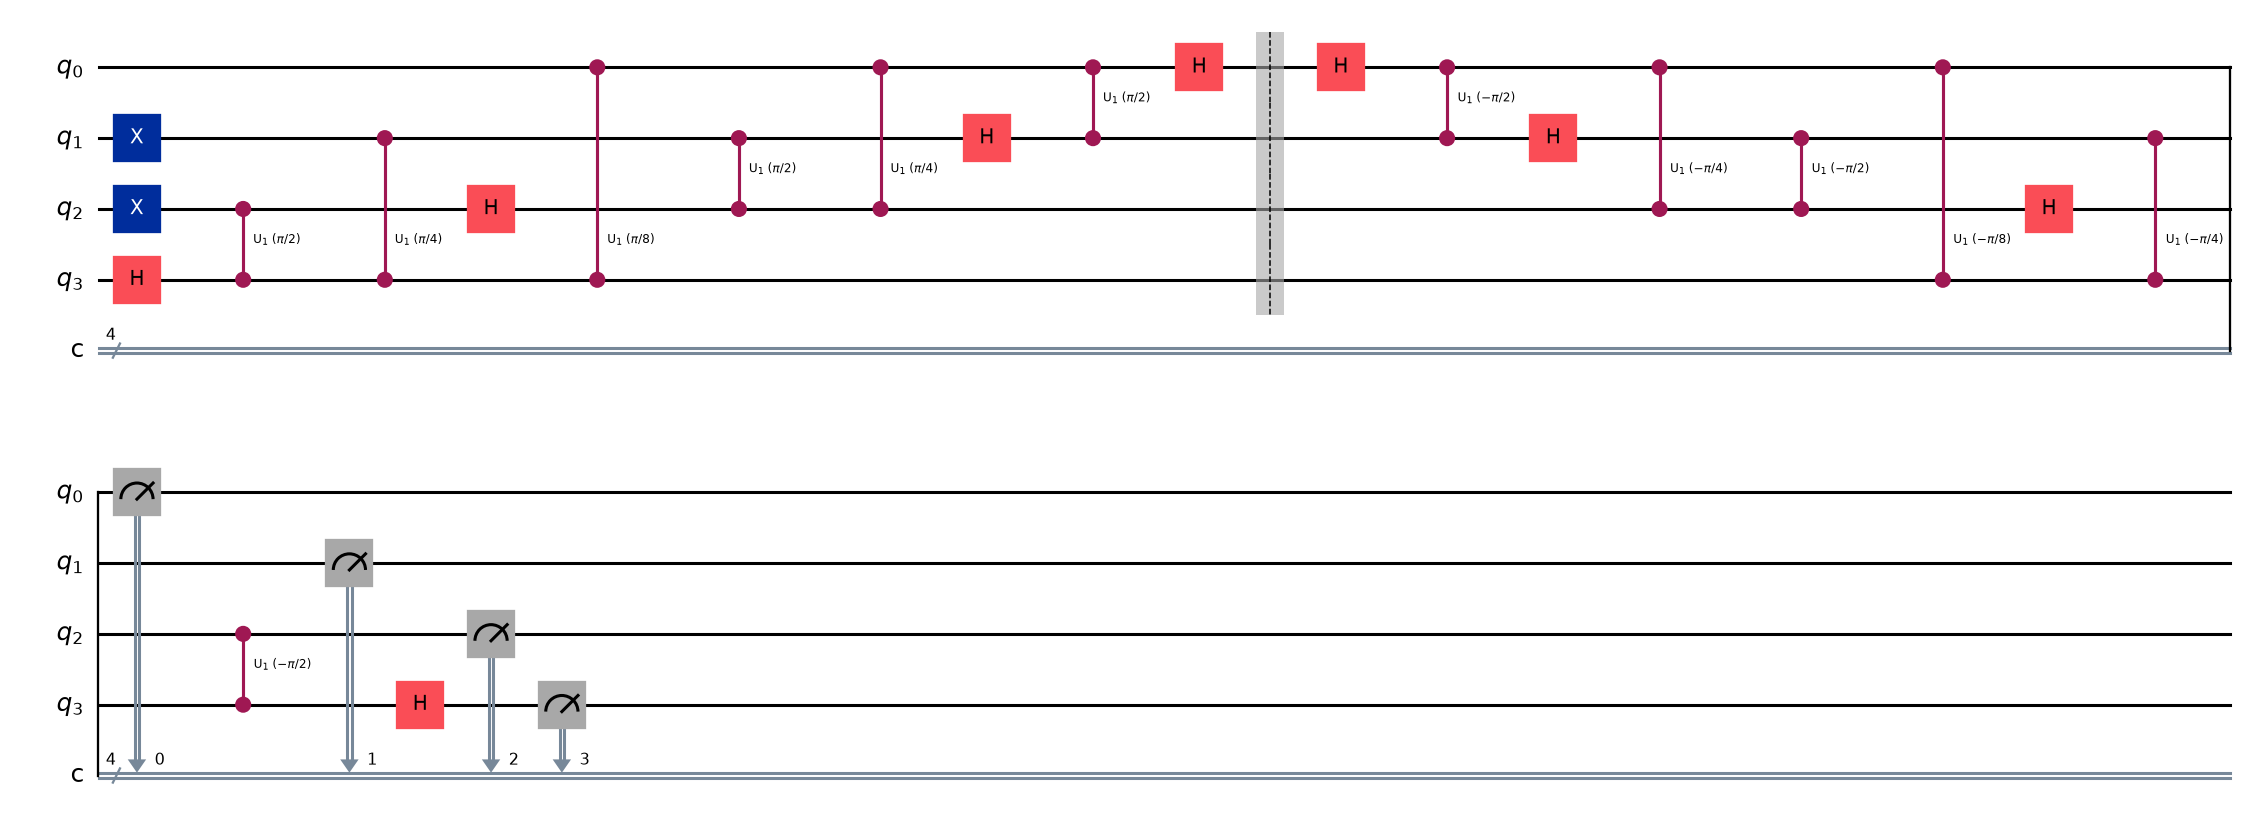

In [6]:
circuit = qft_roundtrip(4, 6)
draw(circuit, fold=30)

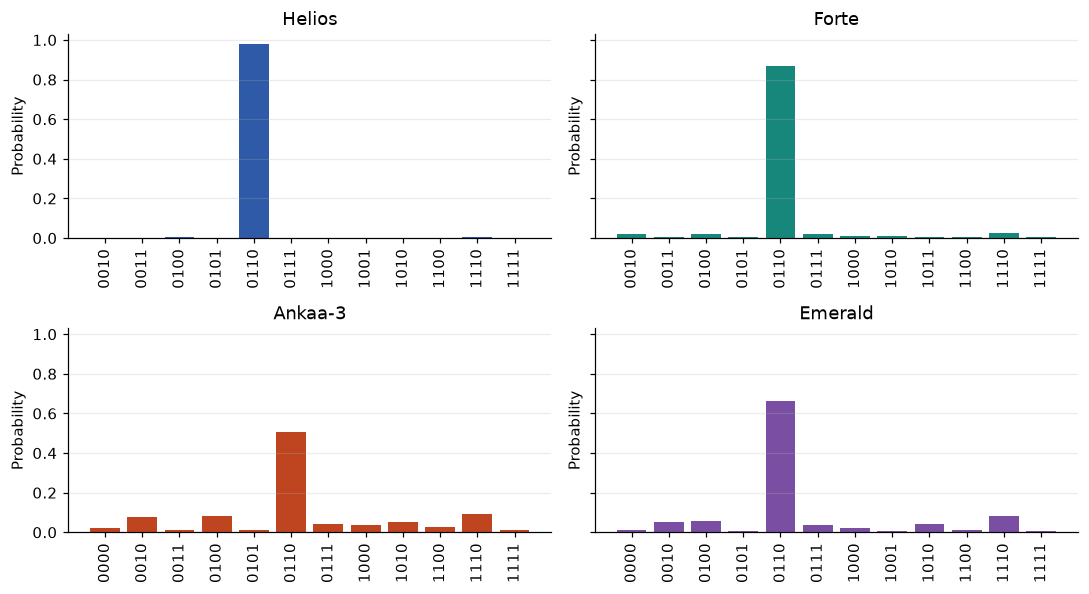

In [7]:
compare("QFT round trip", circuit, ["0110"]);

## Mirror circuit

Random layers followed by their inverse return to all zeros on an ideal device.

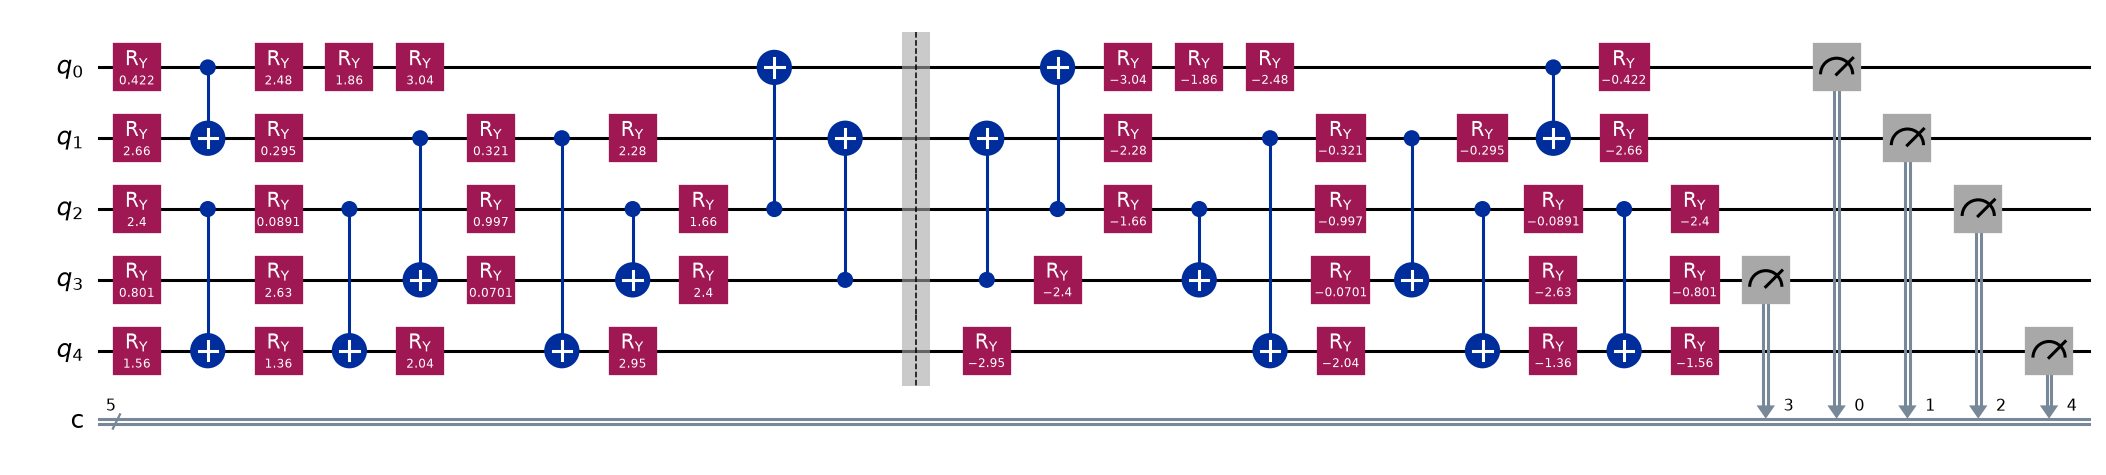

In [8]:
circuit = mirror(5, 4)
draw(circuit, fold=32)

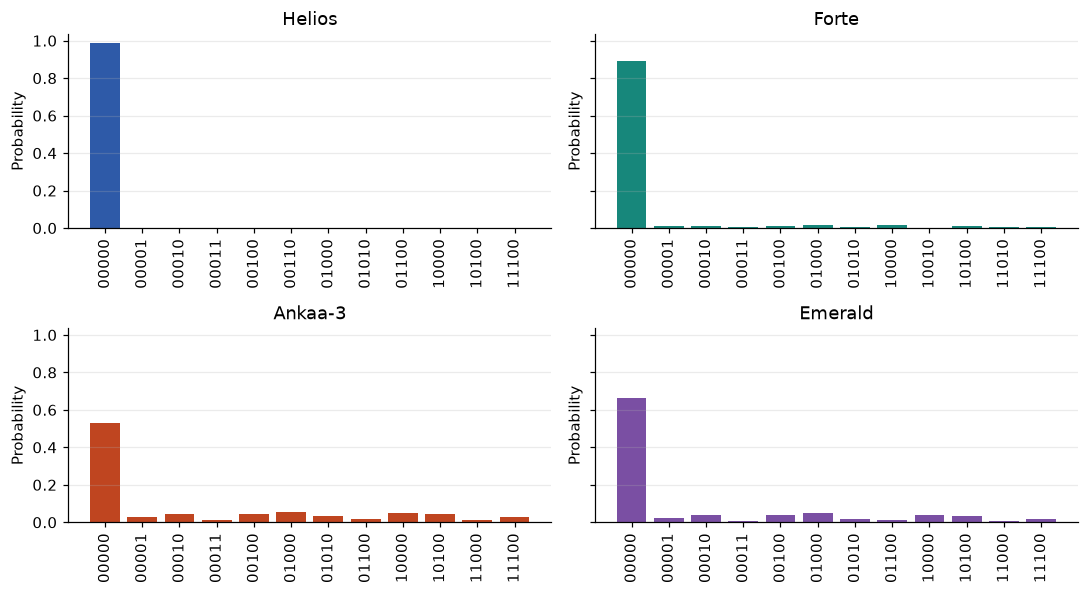

In [9]:
compare("Mirror", circuit, ["00000"]);

## Quantum teleportation

This circuit is dynamic: it measures two qubits mid-circuit and applies corrections based on the results. The final
qubit should be 1 with probability $\sin^2(\theta/2)$, whatever the two intermediate outcomes were.

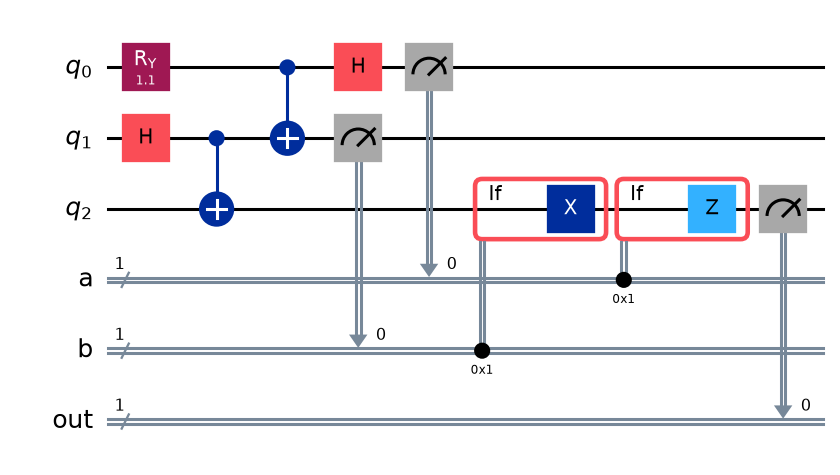

In [10]:
theta = 1.1
circuit = teleportation(theta)
draw(circuit)

In [11]:
expected = math.sin(theta / 2) ** 2

def p_one(counts):
    return sum(v for k, v in counts.items() if k.replace(" ", "")[0] == "1") / sum(counts.values())

ideal = run("ionq_forte", circuit, shots=100_000)
rows = {"Expected": expected, "Ideal engine": p_one(ideal["result"]["counts"])}
for backend in BACKENDS:
    rows[NAMES[backend]] = p_one(run(backend, circuit, noise=True, routing=True, shots=100_000)["result"]["counts"])

print("Execution path on the ideal engine:", ideal["telemetry"]["workload"]["execution_path"])
pd.Series(rows, name="P(teleported qubit = 1)").round(4).to_frame()

Execution path on the ideal engine: shot_branching


,P(teleported qubit = 1)
Expected,0.2732
Ideal engine,0.2741
Helios,0.2750
Forte,0.2815
Ankaa-3,0.3163
Emerald,0.3088


## QAOA for MaxCut

A variational algorithm has a classical optimiser steering quantum jobs, so it sends many short jobs, which is the
kind of workload a cloud service must handle. On a four-node ring the best cut is 4, and one QAOA layer can reach an
average of 3. This sweep sends 169 jobs per twin.

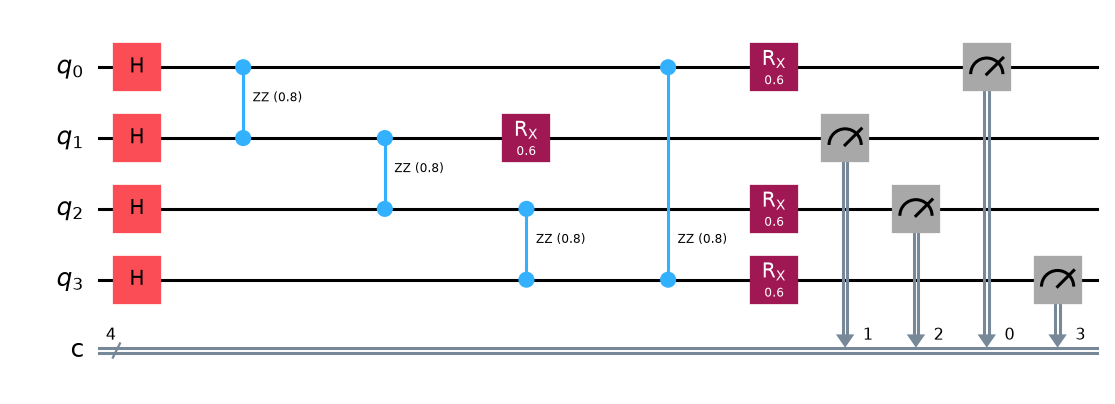

In [12]:
n = 4
draw(qaoa_ring(n, 0.4, 0.3))

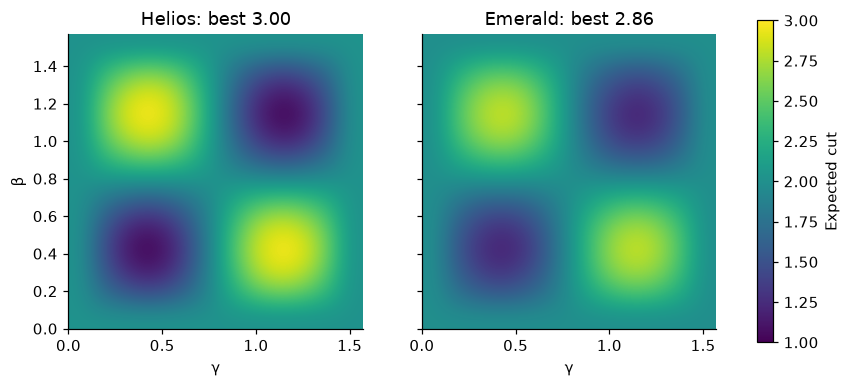

In [13]:
def cut(bits):
    return sum(bits[i] != bits[(i + 1) % n] for i in range(n))

def expected_cut(counts):
    return sum(v * cut(k) for k, v in counts.items()) / sum(counts.values())

gammas = np.linspace(0, np.pi / 2, 13)
betas = np.linspace(0, np.pi / 2, 13)
grids = {}
for backend in ("quantinuum_helios", "iqm_emerald"):
    grids[backend] = np.array([[expected_cut(run(backend, qaoa_ring(n, g, b), noise=True, routing=True, shots=2048)["result"]["counts"])
                                for g in gammas] for b in betas])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
for ax, (backend, grid) in zip(axes, grids.items()):
    image = ax.imshow(grid, origin="lower", extent=[0, np.pi / 2, 0, np.pi / 2], vmin=1, vmax=3, cmap="viridis",
                      interpolation="bicubic")
    ax.set(title=f"{NAMES[backend]}: best {grid.max():.2f}", xlabel="γ")
    ax.grid(False)
axes[0].set_ylabel("β")
fig.colorbar(image, ax=axes, label="Expected cut")
plt.show()

## Scoreboard

Probability of the right answer, for each algorithm on each twin. These reflect published medians and the assumptions
tagged in notebook 01, not measurements on hardware.

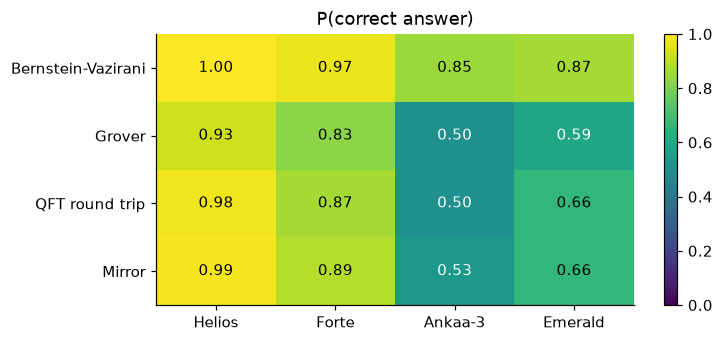

In [14]:
board = pd.DataFrame(scoreboard).T[[NAMES[b] for b in BACKENDS]]

fig, ax = plt.subplots(figsize=(7, 3.2))
image = ax.imshow(board.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set(xticks=range(4), xticklabels=board.columns, yticks=range(len(board)), yticklabels=board.index, title="P(correct answer)")
ax.grid(False)
for (i, j), value in np.ndenumerate(board.values):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if value < 0.6 else "black")
fig.colorbar(image)
plt.show()